**1. ADIM: KÜTÜPHANELERİN EKLENMESİ**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import arff


**2. ADIM: VERİNİN OKUNMASI**

In [28]:
data, meta = arff.loadarff('PhishingData.arff')

# Veriyi DataFrame'e çevirme
df = pd.DataFrame(data)

# Byte tipindeki verileri string ve integera dönüştürme
df = df.applymap(lambda x: x.decode('utf-8') if isinstance(x, bytes) else x)

# İlk 5 satırı görüntüleme
df.head()


C:\Users\sumeyyeduz\AppData\Local\Temp\ipykernel_2076\1766544902.py:7: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(lambda x: x.decode('utf-8') if isinstance(x, bytes) else x)


,SFH,popUpWidnow,SSLfinal_State,Request_URL,URL_of_Anchor,web_traffic,URL_Length,age_of_domain,having_IP_Address,Result
0,1,-1,1,-1,-1,1,1,1,0,0
1,-1,-1,-1,-1,-1,0,1,1,1,1
2,1,-1,0,0,-1,0,-1,1,0,1
3,1,0,1,-1,-1,0,1,1,0,0
4,-1,-1,1,-1,0,0,-1,1,0,1


**3. ADIM: VERİ KEŞFİ VE ÖNİŞLEM**

Veride eksik değer var mı, türler doğru mu gibi kontroller yapacağız.

dtypes: Her sütunun veri tipini gösterir.
isnull().sum(): Her sütunda kaç tane eksik veri olduğunu gösterir.
value_counts(): Sonuç sınıflarının (1, 0, -1) kaç tane olduğunu gösterir.

In [29]:
# Veri tiplerini inceleyelim
print(df.dtypes)

# Eksik veri kontrolü
print(df.isnull().sum())

# Sınıf dağılımını görelim
print(df['Result'].value_counts())


SFH                  object
popUpWidnow          object
SSLfinal_State       object
Request_URL          object
URL_of_Anchor        object
web_traffic          object
URL_Length           object
age_of_domain        object
having_IP_Address    object
Result               object
dtype: object
SFH                  0
popUpWidnow          0
SSLfinal_State       0
Request_URL          0
URL_of_Anchor        0
web_traffic          0
URL_Length           0
age_of_domain        0
having_IP_Address    0
Result               0
dtype: int64
Result
-1    702
1     548
0     103
Name: count, dtype: int64


**4. ADIM: VERİ TİPLERİNİ DÜZELTME (Object → Integer)**

Veri tipleri object görünüyor, ama biz sayısal değerlerle çalışacağız. Bu yüzden sütunları sayısala çevireceğim.

In [30]:
# Tüm sütunları integer tipe dönüştürelim
df = df.astype(int)

# Kontrol için veri tiplerini tekrar gösterelim
print(df.dtypes)

# İlk 5 satırı tekrar görelim
df.head()


SFH                  int32
popUpWidnow          int32
SSLfinal_State       int32
Request_URL          int32
URL_of_Anchor        int32
web_traffic          int32
URL_Length           int32
age_of_domain        int32
having_IP_Address    int32
Result               int32
dtype: object


,SFH,popUpWidnow,SSLfinal_State,Request_URL,URL_of_Anchor,web_traffic,URL_Length,age_of_domain,having_IP_Address,Result
0,1,-1,1,-1,-1,1,1,1,0,0
1,-1,-1,-1,-1,-1,0,1,1,1,1
2,1,-1,0,0,-1,0,-1,1,0,1
3,1,0,1,-1,-1,0,1,1,0,0
4,-1,-1,1,-1,0,0,-1,1,0,1


**5. ADIM: EĞİTİM VE TEST SETLERİNE AYIRMA**

Verimizi makine öğrenmesi modellerine vermeden önce, eğitim ve test seti olarak ikiye ayıracağız. Bunun %20 si test, %80 i eğitim için kullanılacak.

In [31]:
from sklearn.model_selection import train_test_split

# Özellikler (X) ve Etiket (Y) ayırma
X = df.drop('Result', axis=1)
y = df['Result']

# Eğitim ve test setlerine ayırma (80% eğitim, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Setlerin boyutlarına bakalım
print("Eğitim seti boyutu:", X_train.shape)
print("Test seti boyutu:", X_test.shape)


Eğitim seti boyutu: (1082, 9)
Test seti boyutu: (271, 9)


**6. ADIM: MODELLERİN OLUŞTURULMASI VE EĞİTİLMESİ**

Şimdi Logistic Regression (LR) ve K-Nearest Neighbors Classifier (KNC) modellerini oluşturup eğiteceğiz.

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Logistic Regression Modeli Oluşturma ve Eğitme
lr_model = LogisticRegression(max_iter=1000)  #max iterasyon sayısını arttırdık, bazen veri çoksa uyarı veriyor.
lr_model.fit(X_train, y_train)

# K-Nearest Neighbors Classifier Modeli Oluşturma ve Eğitme
knc_model = KNeighborsClassifier(n_neighbors=5)
knc_model.fit(X_train, y_train)

print("Modeller eğitildi.")


Modeller eğitildi.


**7. ADIM: TAHMİNLERİN YAPILMASI VE SONUÇLARIN DEĞERLENDİRİLMESİ**

In [33]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Logistic Regression için tahminler
lr_predictions = lr_model.predict(X_test)

# K-Nearest Neighbors için tahminler
knc_predictions = knc_model.predict(X_test)

# Logistic Regression Sonuçları
print("Logistic Regression Sonuçları")
print("Doğruluk:", accuracy_score(y_test, lr_predictions))  #doğruluk oranını hesaplar.
print("Karışıklık Matrisi:\n", confusion_matrix(y_test, lr_predictions))  #Gerçek ve tahmin edilen değerleri karşılaştırır.
print("Sınıflandırma Raporu:\n", classification_report(y_test, lr_predictions))  #Precision, recall, f1-score gibi detaylı sonnuçları verir.

# K-Nearest Neighbors Sonuçları
print("\nK-Nearest Neighbors Sonuçları")
print("Doğruluk:", accuracy_score(y_test, knc_predictions))
print("Karışıklık Matrisi:\n", confusion_matrix(y_test, knc_predictions))
print("Sınıflandırma Raporu:\n", classification_report(y_test, knc_predictions))


Logistic Regression Sonuçları
Doğruluk: 0.8339483394833949
Karışıklık Matrisi:
 [[119   4   9]
 [ 11   3  11]
 [ 10   0 104]]
Sınıflandırma Raporu:
               precision    recall  f1-score   support

          -1       0.85      0.90      0.88       132
           0       0.43      0.12      0.19        25
           1       0.84      0.91      0.87       114

    accuracy                           0.83       271
   macro avg       0.71      0.64      0.65       271
weighted avg       0.81      0.83      0.81       271


K-Nearest Neighbors Sonuçları
Doğruluk: 0.8523985239852399
Karışıklık Matrisi:
 [[115   4  13]
 [  4  14   7]
 [  9   3 102]]
Sınıflandırma Raporu:
               precision    recall  f1-score   support

          -1       0.90      0.87      0.88       132
           0       0.67      0.56      0.61        25
           1       0.84      0.89      0.86       114

    accuracy                           0.85       271
   macro avg       0.80      0.78      0.79     

**8.ADIM: GRAFİKLERİN EKLENMESİ**

Sınıf Dağılımı Grafiği – Veri setindeki etiketsel dağılımı göstermek için.             
Karışıklık Matrisi (Confusion Matrix) – Modelin ne kadar doğru tahmin yaptığını görselleştirmek için.                   
Doğruluk Karşılaştırma Çizelgesi – Modellerin doğruluk oranlarını karşılaştırmak için.

C:\Users\sumeyyeduz\AppData\Local\Temp\ipykernel_2076\462801930.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['Result'], palette='coolwarm')


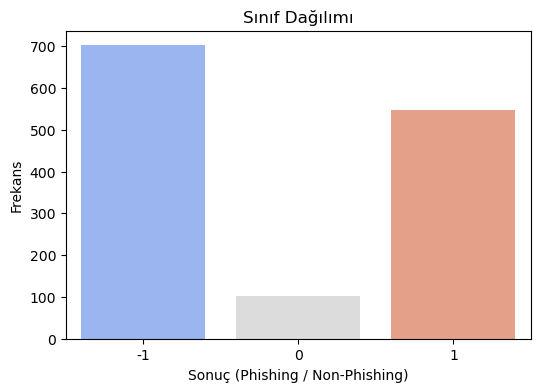

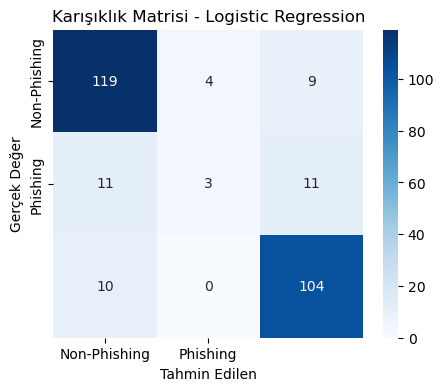

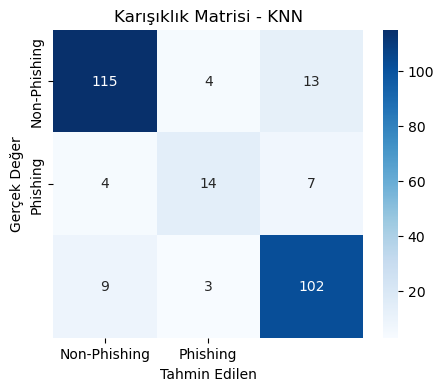

C:\Users\sumeyyeduz\AppData\Local\Temp\ipykernel_2076\462801930.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=models, y=accuracies, palette='viridis')


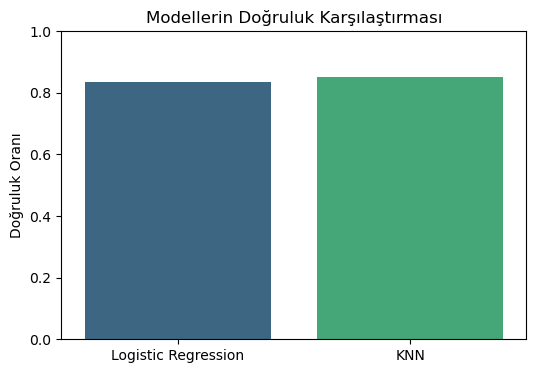

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Sınıf dağılımı grafiği
plt.figure(figsize=(6,4))
sns.countplot(x=df['Result'], palette='coolwarm')
plt.title('Sınıf Dağılımı')
plt.xlabel('Sonuç (Phishing / Non-Phishing)')
plt.ylabel('Frekans')
plt.show()

# 2. Karışıklık Matrisleri
def plot_confusion_matrix(y_true, y_pred, model_name):
    plt.figure(figsize=(5,4))
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Phishing', 'Phishing'], yticklabels=['Non-Phishing', 'Phishing'])
    plt.title(f'Karışıklık Matrisi - {model_name}')
    plt.xlabel('Tahmin Edilen')
    plt.ylabel('Gerçek Değer')
    plt.show()

# Logistic Regression için Karışıklık Matrisi
plot_confusion_matrix(y_test, lr_predictions, "Logistic Regression")

# K-Nearest Neighbors için Karışıklık Matrisi
plot_confusion_matrix(y_test, knc_predictions, "KNN")

# 3. Doğruluk Oranlarının Karşılaştırılması
models = ['Logistic Regression', 'KNN']
accuracies = [accuracy_score(y_test, lr_predictions), accuracy_score(y_test, knc_predictions)]

plt.figure(figsize=(6,4))
sns.barplot(x=models, y=accuracies, palette='viridis')
plt.ylim(0,1)
plt.ylabel('Doğruluk Oranı')
plt.title('Modellerin Doğruluk Karşılaştırması')
plt.show()


**9. ADIM: RANDOM FOREST MODELİ EĞİTME**

C:\Users\sumeyyeduz\AppData\Local\Temp\ipykernel_2076\945827663.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Önem Skoru', y='Özellik', data=feature_importance_df, palette='viridis')


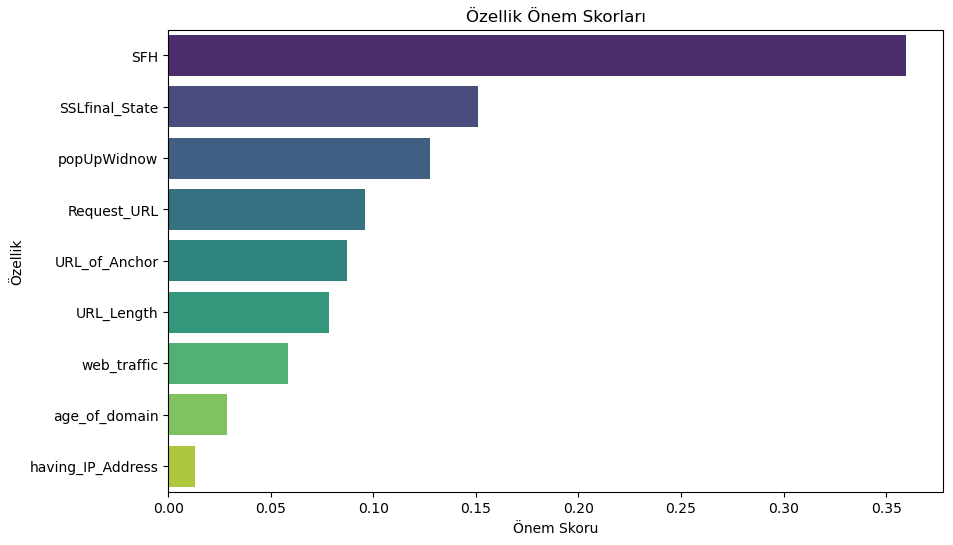

In [35]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest Modeli Eğitme
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Özellik Önem Skorları
feature_importances = rf_model.feature_importances_

# Özellik isimlerini alalım
feature_names = X.columns

# Skorları DataFrame'e çevirme
feature_importance_df = pd.DataFrame({'Özellik': feature_names, 'Önem Skoru': feature_importances})

# Önem skorlarını büyükten küçüğe sıralama
feature_importance_df = feature_importance_df.sort_values(by='Önem Skoru', ascending=False)

# Görselleştirme
plt.figure(figsize=(10,6))
sns.barplot(x='Önem Skoru', y='Özellik', data=feature_importance_df, palette='viridis')
plt.title('Özellik Önem Skorları')
plt.show()


Bu kodu çalıştırarak hangi özelliklerin model tahminleri için daha önemli olduğunu görebiliriz. 

**10. ADIM: ÖNEMSİZ DEĞİŞKENLERİ ÇIKARIP MODELİ YENİDEN EĞİTME**

In [36]:
# Önem skoru belirli bir eşiğin altında olan sütunları belirleyelim
threshold = 0.01  # %1'den az katkı sağlayanları çıkaracağız
low_importance_features = feature_importance_df[feature_importance_df['Önem Skoru'] < threshold]['Özellik'].values

print(f"Çıkarılacak Düşük Öneme Sahip Özellikler: {low_importance_features}")

# Yeni veri kümesini oluşturalım
X_optimized = X.drop(columns=low_importance_features)

# Yeni eğitim ve test setleri
X_train_opt, X_test_opt, y_train_opt, y_test_opt = train_test_split(X_optimized, y, test_size=0.2, random_state=42)

# Logistic Regression Modelini Tekrar Eğitme
lr_model_opt = LogisticRegression(max_iter=1000)
lr_model_opt.fit(X_train_opt, y_train_opt)

# KNN Modelini Tekrar Eğitme
knc_model_opt = KNeighborsClassifier(n_neighbors=5)
knc_model_opt.fit(X_train_opt, y_train_opt)

print("Gereksiz özellikler çıkarıldı ve modeller yeniden eğitildi.")


Çıkarılacak Düşük Öneme Sahip Özellikler: []
Gereksiz özellikler çıkarıldı ve modeller yeniden eğitildi.


**11. ADIM: ESKİ VE YENİ MODELLERİN KARŞILAŞTIRILMASI**

İlk önce tahminleri alacağız. Daha sonra doğruluk oranını hesaplayıp grafik çizdireceğiz. Bu sayede modelde iyileşme olup olmadığını görebiliriz.

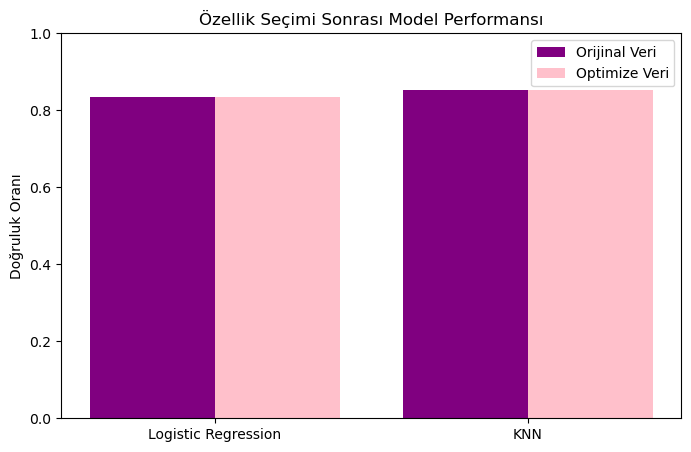

In [37]:
from sklearn.metrics import accuracy_score

# Yeni modellerin tahminleri
lr_predictions_opt = lr_model_opt.predict(X_test_opt)
knc_predictions_opt = knc_model_opt.predict(X_test_opt)

# Eski ve yeni doğruluk skorlarını hesaplayalım
model_names = ["Logistic Regression", "KNN"]
old_accuracies = [accuracy_score(y_test, lr_predictions), accuracy_score(y_test, knc_predictions)]
new_accuracies = [accuracy_score(y_test_opt, lr_predictions_opt), accuracy_score(y_test_opt, knc_predictions_opt)]

# Görselleştirme
x = np.arange(len(model_names))  # x ekseni için indeksler

plt.figure(figsize=(8,5))
plt.bar(x - 0.2, old_accuracies, width=0.4, label='Orijinal Veri', color='purple')
plt.bar(x + 0.2, new_accuracies, width=0.4, label='Optimize Veri', color='pink')

plt.xticks(x, model_names)
plt.ylim(0,1)
plt.ylabel('Doğruluk Oranı')
plt.title('Özellik Seçimi Sonrası Model Performansı')
plt.legend()
plt.show()


**12. ADIM: HİPERPARAMETRE OPTİMİZASYONU**

GridSearchCV ile en iyi parametreleri bulacağız. Daha sonra optimum parametrelerle modelleri yeniden eğitip yeni doğruluk oranlarını hesaplayıp kıyaslayalım.

En İyi Logistic Regression Parametreleri: {'C': 10, 'solver': 'lbfgs'}
En İyi KNN Parametreleri: {'n_neighbors': 5, 'weights': 'distance'}


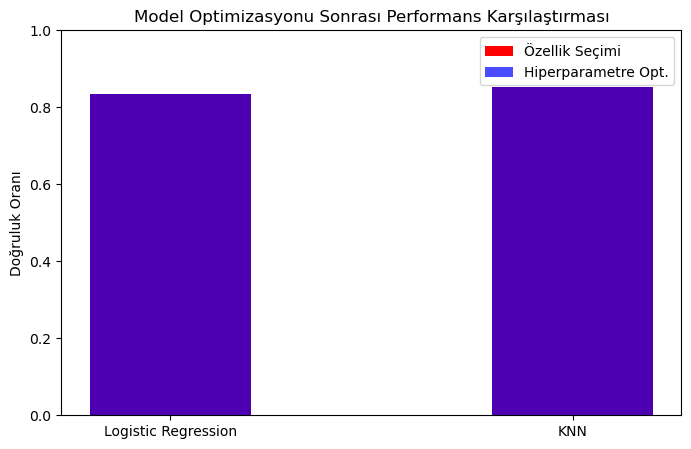

In [38]:
from sklearn.model_selection import GridSearchCV

# Logistic Regression için hiperparametre araması
lr_params = {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear']}
lr_grid = GridSearchCV(LogisticRegression(max_iter=1000), lr_params, cv=5, scoring='accuracy')
lr_grid.fit(X_train_opt, y_train_opt)

# En iyi Logistic Regression modelini al
best_lr = lr_grid.best_estimator_
print("En İyi Logistic Regression Parametreleri:", lr_grid.best_params_)

# KNN için hiperparametre araması
knc_params = {'n_neighbors': [3, 5, 7, 9], 'weights': ['uniform', 'distance']}
knc_grid = GridSearchCV(KNeighborsClassifier(), knc_params, cv=5, scoring='accuracy')
knc_grid.fit(X_train_opt, y_train_opt)

# En iyi KNN modelini al
best_knc = knc_grid.best_estimator_
print("En İyi KNN Parametreleri:", knc_grid.best_params_)

# Optimum modellerle test seti doğruluklarını hesaplayalım
lr_best_pred = best_lr.predict(X_test_opt)
knc_best_pred = best_knc.predict(X_test_opt)

# Yeni doğruluk skorları
optimized_accuracies = [accuracy_score(y_test_opt, lr_best_pred), accuracy_score(y_test_opt, knc_best_pred)]

# Karşılaştırma grafiği
plt.figure(figsize=(8,5))
plt.bar(model_names, new_accuracies, width=0.4, label='Özellik Seçimi', color='red')
plt.bar(model_names, optimized_accuracies, width=0.4, label='Hiperparametre Opt.', color='blue', alpha=0.7)

plt.ylim(0,1)
plt.ylabel('Doğruluk Oranı')
plt.title('Model Optimizasyonu Sonrası Performans Karşılaştırması')
plt.legend()
plt.show()


**13. ADIM: RANDOM FOREST MODELİNİ EĞİTME**

In [39]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest modelini oluştur ve eğit
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Tahmin yap
rf_predictions = rf_model.predict(X_test)

# Sonuçları yazdır
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Random Forest Sonuçları")
print("Doğruluk:", accuracy_score(y_test, rf_predictions))
print("Karışıklık Matrisi:\n", confusion_matrix(y_test, rf_predictions))
print("Sınıflandırma Raporu:\n", classification_report(y_test, rf_predictions))


Random Forest Sonuçları
Doğruluk: 0.8782287822878229
Karışıklık Matrisi:
 [[119   2  11]
 [  2  20   3]
 [ 13   2  99]]
Sınıflandırma Raporu:
               precision    recall  f1-score   support

          -1       0.89      0.90      0.89       132
           0       0.83      0.80      0.82        25
           1       0.88      0.87      0.87       114

    accuracy                           0.88       271
   macro avg       0.87      0.86      0.86       271
weighted avg       0.88      0.88      0.88       271



**14. ADIM: Modellerin Karşılaştırılması (Grafik)**

C:\Users\sumeyyeduz\AppData\Local\Temp\ipykernel_2076\4132569140.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=models, y=accuracies, palette='coolwarm')


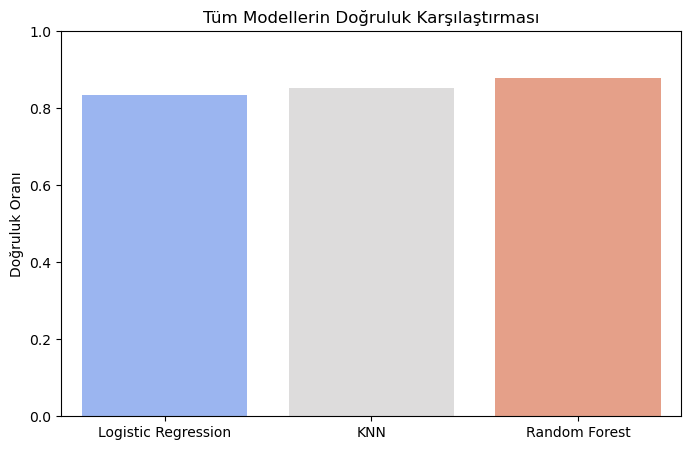

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

# Modellerin doğruluk oranlarını karşılaştıralım
models = ['Logistic Regression', 'KNN', 'Random Forest']
accuracies = [
    accuracy_score(y_test, lr_predictions), 
    accuracy_score(y_test, knc_predictions), 
    accuracy_score(y_test, rf_predictions)
    
]

plt.figure(figsize=(8,5))
sns.barplot(x=models, y=accuracies, palette='coolwarm')
plt.ylim(0,1)
plt.ylabel('Doğruluk Oranı')
plt.title('Tüm Modellerin Doğruluk Karşılaştırması')
plt.show()
